# blindside walkthrough

**Who is pressed from the blind side? Broadcast body pose against the XY proxy, with honest uncertainty.**

This notebook is stored with its outputs, so it reads in the browser without installing anything.
It runs the package on the 12.3 s sample phase of SkillCorner's open data (match 1925299, 309 pose frames),
the same data as `uv run blindside reproduce --fast`.

What the sample can and cannot show:

- It shows **how the package is called** and what its three kinds of figures look like.
- It holds two on-ball engagements. It **does not reproduce a result**. The figures below are stand-ins,
  each stamped as such. The figures of the full run on both matches are at the end, for comparison.
- No outcome column is read anywhere in this notebook.

To run it yourself from the repository root (the first run downloads about 100 MB, verified by sha256):

```
uv sync
uv run --with jupyter jupyter lab examples/walkthrough.ipynb
```

In [8]:
%matplotlib inline
import os
from pathlib import Path

# The package keeps downloads and caches in ./data. Work from the repository root, not examples/.
if Path.cwd().name == "examples":
    os.chdir("..")

## 1. The core idea in ten lines

A facing direction comes from two joints, here the ears. Every joint ships with a predicted error (`p90_mae_cm`).
`sample_facing_angles` propagates that error into samples of the facing angle, and `blind_side_probability`
is the share of samples for which the presser lies outside a visual field of 100 degrees to each side.

The true angular error is unknown, so everything is computed under two bounds: `lower` (as small as the
frame-to-frame jitter suggests) and `upper` (independent joint errors, Monte Carlo).

In [9]:
import numpy as np

from blindside import blind_side_probability, bound_correlation, sample_facing_angles

# Carrier facing +x, ears 18 cm apart, 6 cm p90 error, presser behind the left shoulder.
ears = dict(left_xy=[[0.0, 0.09]], right_xy=[[0.0, -0.09]], left_p90_cm=[6.0], right_p90_cm=[6.0])
for bound in ("lower", "upper"):
    rho = bound_correlation("head", bound)
    facing = sample_facing_angles(**ears, correlation=rho, rng=np.random.default_rng(0))
    p = blind_side_probability(facing, carrier_xy=[[0.0, 0.0]], presser_xy=[[-1.0, 3.0]])
    print(f"p_blind_side, {bound} bound: {p[0]:.2f}")

p_blind_side, lower bound: 1.00
p_blind_side, upper bound: 0.73


The same presser is certainly unseen under the lower bound and unseen in 73% of the samples under the upper bound.
That gap is why `p_blind_side` is always reported under both.

## 2. Orientation with uncertainty for every pose of the clip

`cached_orientation_table` streams a pose file and returns one row per player and frame: torso, hip and head
facing with the angular standard deviation under both bounds.

In [10]:
import pandas as pd
from IPython.display import display  # type: ignore

from blindside import cached_orientation_table, load_match_metadata, sample_pose_file

MATCH_ID = 1925299
STAMP = "SAMPLE PHASE (12.3 s of match 1925299), a smoke test, not the README figure."

sample = sample_pose_file()
table = cached_orientation_table(sample, MATCH_ID)
print(f"{len(table):,} poses in {table['frame'].nunique()} frames of {sample.name}")

segments = ("torso", "hips", "head")
summary = pd.DataFrame(
    {
        "poses": [int(table[f"{s}_deg"].notna().sum()) for s in segments],
        "median SD, lower bound (deg)": [table[f"{s}_sd_low_deg"].median() for s in segments],
        "median SD, upper bound (deg)": [table[f"{s}_sd_deg"].median() for s in segments],
    },
    index=list(segments),
).round(1)
display(summary)

4,953 poses in 309 frames of sample_1925299_phase406.jsonl.gz


,poses,"median SD, lower bound (deg)","median SD, upper bound (deg)"
torso,4953,1.3,5.0
hips,4953,2.2,12.3
head,4953,1.9,12.5


The torso is the most stable segment because the shoulders are the widest baseline (about 0.37 m against 0.22 m for
the hips and 0.18 m for the ears). The same joint error turns into more angular noise on a shorter baseline.

## 3. Figure kind 1: the reliability map

Where and when is pose-derived orientation usable? The composite shows the bracket between both bounds by player
speed, the pitch zones, and a check that needs no ground truth: at running speed the hips should face the
direction of travel.

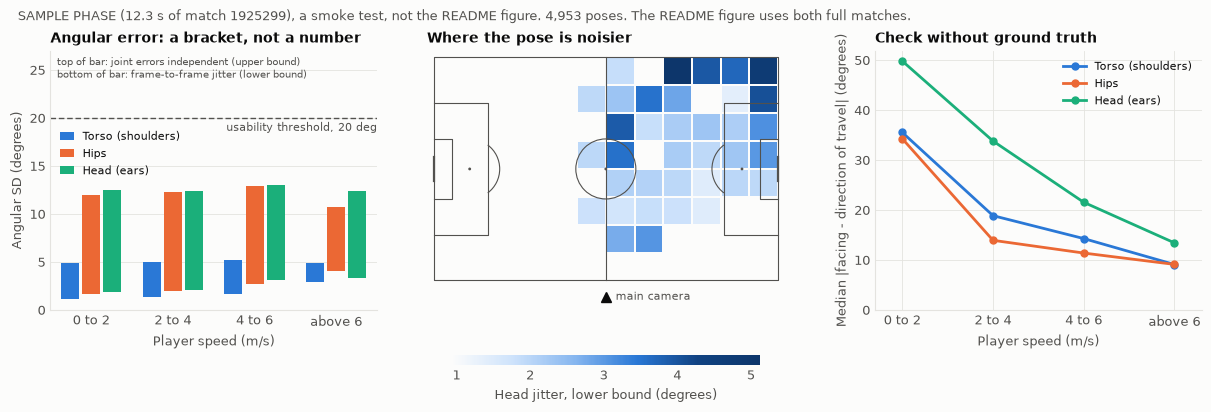

In [11]:
from blindside.analysis.camera import estimate_camera, read_corners
from blindside.analysis.pipeline import reliability_inputs
from blindside.viz.reliability import plot_reliability_composite

metadata = load_match_metadata(MATCH_ID)
pitch_dims = (float(metadata["pitch_length"]), float(metadata["pitch_width"]))

_, periods, corners = read_corners(sample, step=1)
camera = estimate_camera(corners, periods, MATCH_ID) if len(corners) else None
camera_side = camera.side if camera is not None and camera.reliable else None

inputs = reliability_inputs(table, {MATCH_ID: pitch_dims}, min_zone_poses=20)
plot_reliability_composite(
    **inputs.composite(),  # type: ignore
    camera_side=camera_side,
    caption=f"{STAMP} {len(table):,} poses. The README figure uses both full matches.",
)

## 4. Figure kind 2: both blind-side labels on single engagements

Now the applied metric. For each on-ball engagement of the clip the package joins presser and carrier to their
poses and computes `p_blind_side` under both bounds. The XY proxy that analysts use without body pose is drawn
next to it: the presser counts as blind if they are more than 100 degrees off the carrier's direction of travel.

In [12]:
from blindside import classify_xy_reliability, pose_feature_table
from blindside.analysis.pipeline import engagement_geometry
from blindside.data.manifest import POSE_FPS
from blindside.data.tracking import cached_positions, download_tracking, position_grid
from blindside.features.pose_features import (
    BOUNDS,
    FOV_HALF_ANGLE_DEG,
    read_engagement_poses,
    select_pose_frames,
)
from blindside.features.xy_baseline import baseline_table

download_tracking(MATCH_ID)  # 90 MB on first use, for the direction of travel
engagements = baseline_table(MATCH_ID, with_outcomes=False)
engagements["pose_frame"] = select_pose_frames(engagements, table[["frame", "player_id"]])
engagements = engagements[(engagements["pose_frame"] >= 0) & engagements["has_tracking"]]
engagements = engagements.reset_index(drop=True)

frames = engagements["pose_frame"].tolist()
wanted = set(zip(frames, engagements["presser_id"].tolist(), strict=True)) | set(
    zip(frames, engagements["carrier_id"].tolist(), strict=True)
)
poses = read_engagement_poses(sample, wanted, MATCH_ID)
features = {bound: pose_feature_table(engagements, poses, bound=bound) for bound in BOUNDS}

grid = position_grid(cached_positions(MATCH_ID))
geometry = engagement_geometry(engagements, poses, features, grid)
geometry["time_s"] = (engagements["pose_frame"] - int(table["frame"].min())) / POSE_FPS

overview = geometry[["time_s", "carrier_speed", "approach_angle_heading_deg"]].round(1)
overview["xy_proxy"] = np.where(
    geometry["approach_angle_heading_deg"] > FOV_HALF_ANGLE_DEG, "blind", "in view"
)
overview["xy_proxy_is"] = classify_xy_reliability(geometry["carrier_speed"])
for bound in BOUNDS:
    overview[f"p_blind_side_head, {bound}"] = geometry[f"p_head_{bound}"].round(2)
display(overview)

,time_s,carrier_speed,approach_angle_heading_deg,xy_proxy,xy_proxy_is,"p_blind_side_head, lower","p_blind_side_head, upper"
0,2.9,3.7,106.2,blind,intermediate,0.0,0.00
1,6.8,6.8,145.2,blind,reliable,1.0,0.96


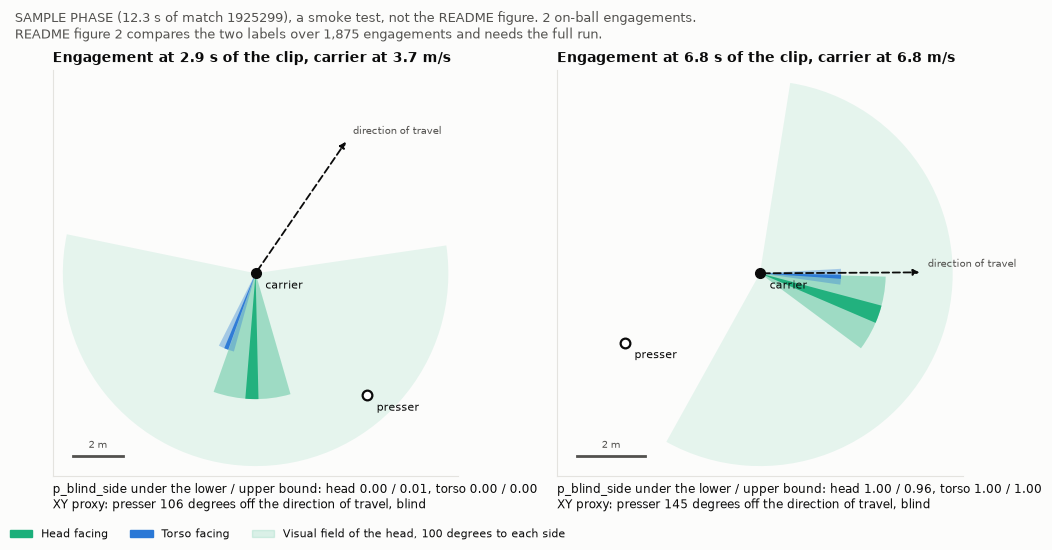

In [13]:
from blindside.viz.agreement import plot_engagement_geometry

plot_engagement_geometry(
    geometry,
    half_angle_deg=FOV_HALF_ANGLE_DEG,
    caption=f"{STAMP} {len(geometry)} on-ball engagements.\n"
    "README figure 2 compares the two labels over 1,875 engagements and needs the full run.",
)

`classify_xy_reliability` is the helper for matches without body pose. Across both full matches the XY proxy agrees
with the pose label barely beyond chance when the carrier moves below 2 m/s (Cohen's kappa 0.09) and becomes a
workable stand-in from 4 m/s (kappa 0.54 and above). Agreement is not accuracy: without ground truth for
orientation, nobody can say which label is right.

## 5. Figure kind 3: one press on the pitch

The same engagement geometry on an `mplsoccer` pitch: the head facing with the visual field and both bounds of its
angular error at the edges, the direction of travel with the field the XY proxy assumes, the run of both players
over the two seconds before the engagement, and the exact values.

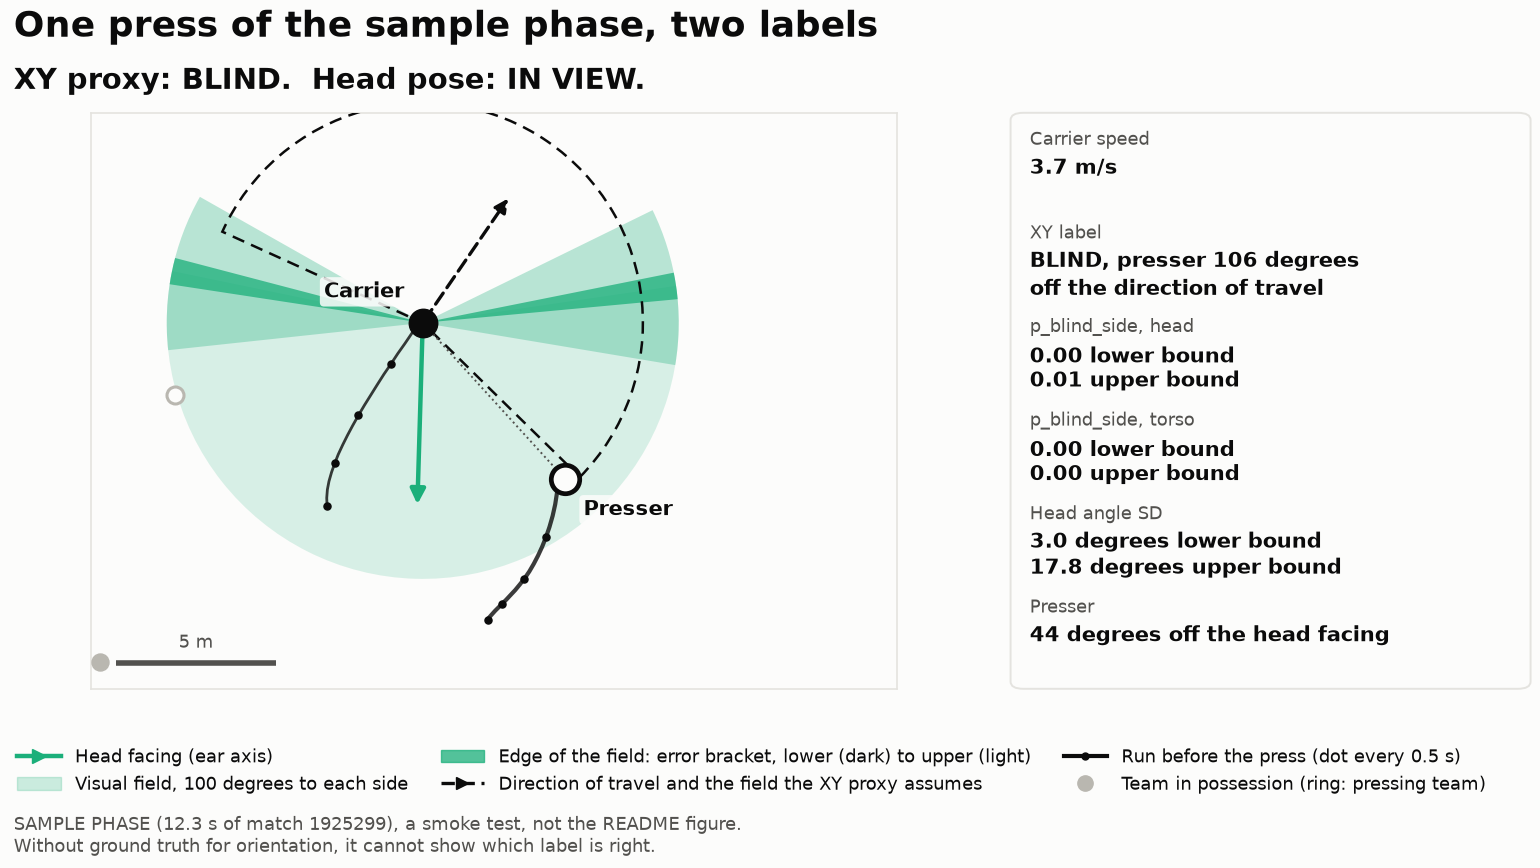

In [14]:
from blindside.analysis.scene import other_players, run_path
from blindside.viz.case_study import plot_scene_cone

PICK = 0  # which engagement of the clip to draw
engagement = engagements.iloc[PICK]
scene = geometry.iloc[PICK].copy()
scene["presser_off_head_deg"] = features["upper"]["presser_off_head_deg"].iloc[PICK]
paths = {
    player: run_path(grid, int(engagement["frame_start"]), int(engagement[f"{player}_id"]))
    for player in ("carrier", "presser")
}
plot_scene_cone(
    scene,
    other_players(engagement, grid),
    pitch_dims,
    paths,
    half_angle_deg=FOV_HALF_ANGLE_DEG,
    headline="One press of the sample phase, two labels",
    caption=f"{STAMP}\nWithout ground truth for orientation, it cannot show which label is right.",
)

## 6. The same three figures from the full run

The figures above are smoke tests on 12.3 seconds. These are the committed figures of
`uv run blindside reproduce --with-scene` on both pose matches (1.4 GB download, about 13 minutes).

**Reliability of pose-derived orientation** (README figure 1)

![Reliability of pose-derived orientation](../docs/figures/reliability_composite.png)

**XY proxy against the pose blind-side label by carrier speed** (README figure 2). Exploratory, no outcome used.
Kappa measures agreement, not accuracy.

![XY proxy against the pose blind-side label](../docs/figures/proxy_agreement.png)

**One slow-carrier press on which the two labels disagree.** The clearest of 82 candidates of a fixed rule that reads
no outcome, not a typical engagement.

![One press, two labels](../docs/figures/match_scene_cone.png)

## 7. What this notebook did not show

- **The pre-registered test.** Adding the pose features to an XY baseline changed the out-of-sample log loss for
  possession loss by minus 0.0002: no detectable increment. With 217 events an odds ratio between 0.84 and 1.47 per
  standard deviation could not have been told from 1. `p_blind_side` is implemented and geometrically verified,
  not validated as an explanatory variable. See [docs/INCREMENTAL.md](../docs/INCREMENTAL.md).
- **Descriptive profiles** of pressers, carriers and pitch zones:
  [docs/TACTICAL_INSIGHTS.md](../docs/TACTICAL_INSIGHTS.md).
- **Everything else**: the [README](../README.md).